In [2]:
# Import libraries
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd




from urllib.request import urlopen
import json
from IPython.display import Image

import plotly.io as pio
import plotly.express as px       # 편리한 plot 설정 
import plotly.graph_objects as go # 디테일하게 plot을 설정
import plotly.figure_factory as ff
from plotly.subplots import make_subplots

In [3]:
# 한글폰트 설정
plt.rc("font", family="Malgun Gothic")
# 레티나 디스플레이로 폰트를 선명하게 표시
# from IPython.display import set_matplotlib_formats
# set_matplotlib_formats("retina")

%config InlineBackend.figure_format = 'retina'

pd.options.display.float_format = '{:20.3f}'.format

pd.set_option('display.max_rows', None)
# pd.options.display.max_rows = 60

## 1. 시도별 종사자수 데이터

In [4]:
industry = pd.read_csv('data/시도_산업별_사업체수__종사자수_및_매출액_20220702222322.csv')
industry

,행정구역별,산업코드,산업별,시점,사업체수 (개),종사자수 (명),매출액 (백만원)
0,전국,NaN,전체 산업,2016,3950169,21259126,5462931383
1,전국,NaN,전체 산업,2017,4019872,21626904,5836148173
2,전국,NaN,전체 산업,2018,4103172,22234776,6033068539
3,전국,NaN,전체 산업,2019,4176549,22723272,6195097953
4,전국,A,"농업, 임업 및 어업(01~03)",2016,3627,39650,11197171
5,전국,A,"농업, 임업 및 어업(01~03)",2017,3880,40642,12361469
6,전국,A,"농업, 임업 및 어업(01~03)",2018,4261,42324,12328862
7,전국,A,"농업, 임업 및 어업(01~03)",2019,4522,43920,12770943
8,전국,B,광업(05~08),2016,2012,15861,4386825
9,전국,B,광업(05~08),2017,2001,15421,4433557


In [5]:
industry.rename(columns = {'행정구역별':'sido', 
                           '산업코드':'code', 
                           '산업별':'sector', 
                           '시점':'year',
                           '사업체수 (개)':'firm', 
                           '종사자수 (명)':'employee',
                           '매출액 (백만원)':'sales'}, inplace = True)
industry.head()

,sido,code,sector,year,firm,employee,sales
0,전국,NaN,전체 산업,2016,3950169,21259126,5462931383
1,전국,NaN,전체 산업,2017,4019872,21626904,5836148173
2,전국,NaN,전체 산업,2018,4103172,22234776,6033068539
3,전국,NaN,전체 산업,2019,4176549,22723272,6195097953
4,전국,A,"농업, 임업 및 어업(01~03)",2016,3627,39650,11197171


In [6]:
industry = industry.query("sector != '전체 산업' & sido != '전국'")
industry

,sido,code,sector,year,firm,employee,sales
84,서울,A,"농업, 임업 및 어업(01~03)",2016,25,464,324115
85,서울,A,"농업, 임업 및 어업(01~03)",2017,29,469,424448
86,서울,A,"농업, 임업 및 어업(01~03)",2018,30,462,235636
87,서울,A,"농업, 임업 및 어업(01~03)",2019,24,426,241961
88,서울,B,광업(05~08),2016,22,58,8773
89,서울,B,광업(05~08),2017,21,66,7600
90,서울,B,광업(05~08),2018,24,81,25979
91,서울,B,광업(05~08),2019,20,43,13788
92,서울,C,제조업(10~34),2016,62150,278773,54031840
93,서울,C,제조업(10~34),2017,61583,277920,53226690


In [7]:
# 기본적으로 y축은 합계로 나타나며 color 옵션을 주면 stack 형태로 나타난다.
fig = px.bar(industry, 
             x="sido", 
             y="employee", 
             color="sector",  
             template="simple_white",
             facet_col = 'year', 
             facet_col_wrap = 1,
             height = 1000
)
fig.show()

In [8]:
# 2019년 데이터만 추출
industry_2019 = industry.loc[industry['year']==2019, ['sido','code','sector','employee']]


industry_2019.sample(n=10)

,sido,code,sector,employee
1255,경북,M,"전문, 과학 및 기술 서비스업(70~73)",27946
695,세종,M,"전문, 과학 및 기술 서비스업(70~73)",6755
411,광주,B,광업(05~08),41
903,충북,E,"수도, 하수 및 폐기물 처리, 원료 재생업(36~39)",5454
235,부산,R,"예술, 스포츠 및 여가관련 서비스업(90~91)",24997
191,부산,G,도매 및 소매업(45~47),234742
1431,제주,Q,보건업 및 사회복지 서비스업(86~87),25268
523,대전,J,정보통신업(58~63),14990
1195,전남,R,"예술, 스포츠 및 여가관련 서비스업(90~91)",16645
1111,전북,Q,보건업 및 사회복지 서비스업(86~87),86679


In [9]:
fig = px.bar(industry_2019, 
             x="sido", 
             y="employee", 
             color="sector", 
             template="simple_white"
            )
fig.show()

## 2. LQ 분석

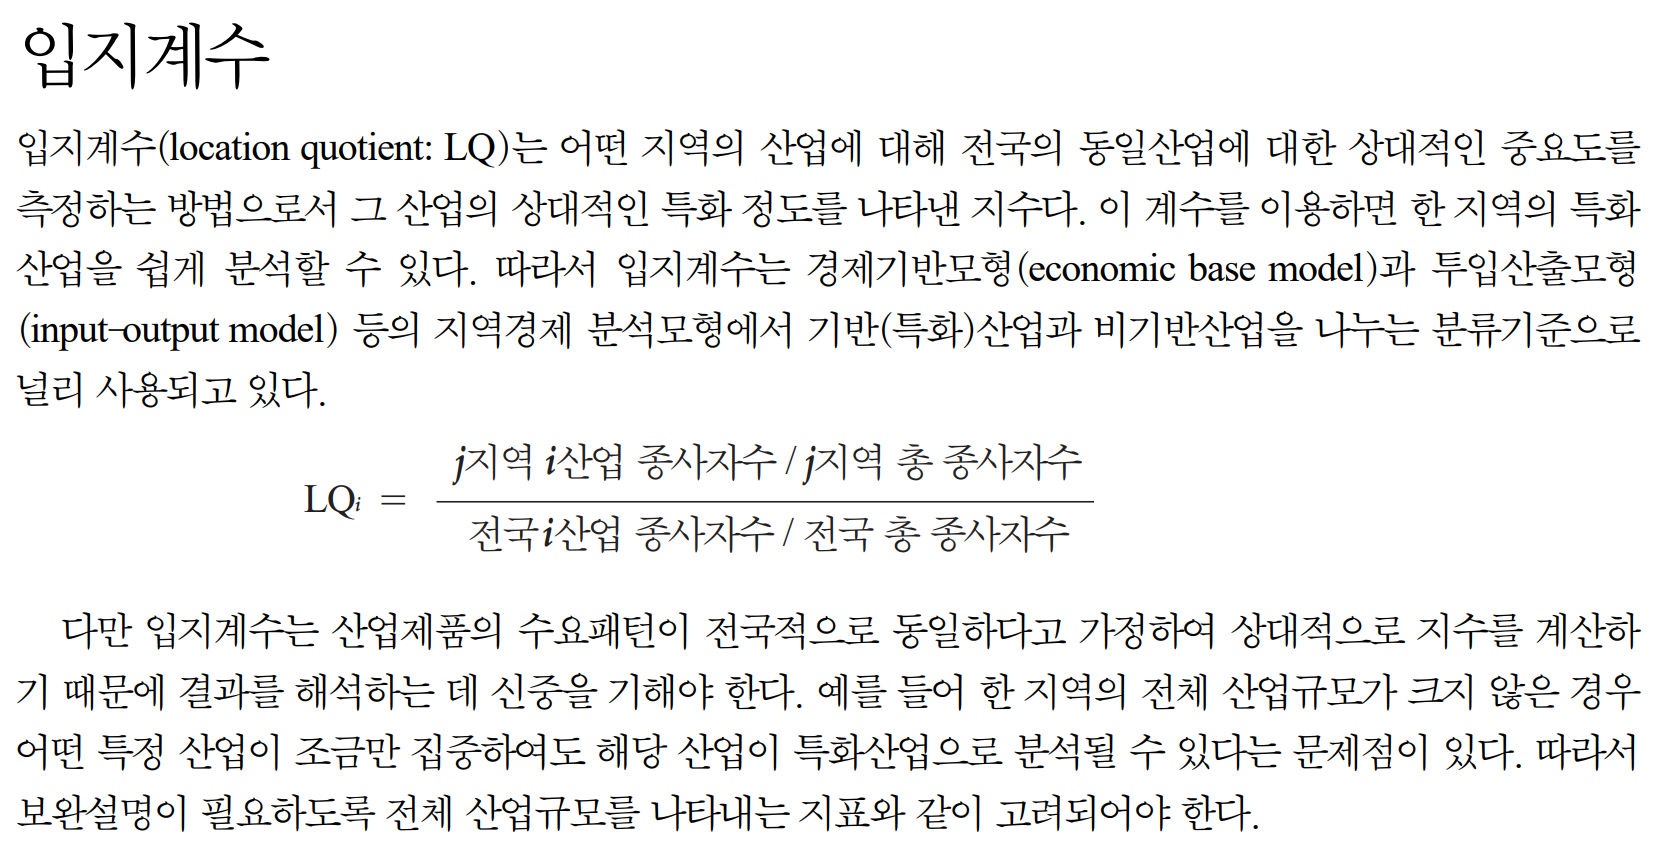

In [10]:
Image(filename="image/LQ.PNG")

In [11]:
# j지역 총 종사자수
industry_2019.groupby(['sido'])[['employee']].agg(['sum']).droplevel(axis=1,level=1).reset_index().rename(columns = {'employee' : 'emp_sum'})

,sido,emp_sum
0,강원,670247
1,경기,5302740
2,경남,1427443
3,경북,1150047
4,광주,631876
5,대구,967934
6,대전,633418
7,부산,1465433
8,서울,5226997
9,세종,125410


In [12]:
# j지역 총 종사자수 변수생성

gb = industry_2019.groupby(["sido"])["employee"] # Group 설정
print(gb)

industry_2019["sido_sum"] = gb.transform("sum") # 설정된 그룹에 "Sum" 적용
industry_2019.head(40)

,sido,code,sector,employee,sido_sum
87,서울,A,"농업, 임업 및 어업(01~03)",426,5226997
91,서울,B,광업(05~08),43,5226997
95,서울,C,제조업(10~34),265273,5226997
99,서울,D,"전기, 가스, 증기 및 공기조절 공급업(35)",6234,5226997
103,서울,E,"수도, 하수 및 폐기물 처리, 원료 재생업(36~39)",9158,5226997
107,서울,F,건설업(41~42),362785,5226997
111,서울,G,도매 및 소매업(45~47),899642,5226997
115,서울,H,운수 및 창고업(49~52),264181,5226997
119,서울,I,숙박 및 음식점업(55~56),493912,5226997
123,서울,J,정보통신업(58~63),360062,5226997


In [13]:
# 전국 i산업 종사자수
industry_2019.groupby(['code'])[['employee']].agg(['sum']).droplevel(axis=1,level=1).reset_index().rename(columns = {'employee' : 'emp_sum'})

,code,emp_sum
0,A,43920
1,B,14887
2,C,4123817
3,D,67526
4,E,114085
5,F,1504466
6,G,3289652
7,H,1155965
8,I,2384828
9,J,606964


In [14]:
# 전국 i산업 종사자수 변수 생성
gb = industry_2019.groupby(["code"])["employee"]

industry_2019["sector_sum"] = gb.transform("sum")
industry_2019.sort_values('code')

,sido,code,sector,employee,sido_sum,sector_sum
87,서울,A,"농업, 임업 및 어업(01~03)",426,5226997,43920
407,광주,A,"농업, 임업 및 어업(01~03)",341,631876,43920
1047,전북,A,"농업, 임업 및 어업(01~03)",3918,720052,43920
487,대전,A,"농업, 임업 및 어업(01~03)",388,633418,43920
327,인천,A,"농업, 임업 및 어업(01~03)",209,1092494,43920
1207,경북,A,"농업, 임업 및 어업(01~03)",4877,1150047,43920
967,충남,A,"농업, 임업 및 어업(01~03)",4662,973944,43920
567,울산,A,"농업, 임업 및 어업(01~03)",178,533187,43920
247,대구,A,"농업, 임업 및 어업(01~03)",414,967934,43920
887,충북,A,"농업, 임업 및 어업(01~03)",2716,741452,43920


In [15]:
# 전국 총 종사자수 변수 생성

industry_2019["total_sum"] = industry_2019["employee"].sum()
industry_2019.head()

,sido,code,sector,employee,sido_sum,sector_sum,total_sum
87,서울,A,"농업, 임업 및 어업(01~03)",426,5226997,43920,22723272
91,서울,B,광업(05~08),43,5226997,14887,22723272
95,서울,C,제조업(10~34),265273,5226997,4123817,22723272
99,서울,D,"전기, 가스, 증기 및 공기조절 공급업(35)",6234,5226997,67526,22723272
103,서울,E,"수도, 하수 및 폐기물 처리, 원료 재생업(36~39)",9158,5226997,114085,22723272


In [16]:
# LQ 변수 생성

industry_2019["LQ"] = (industry_2019.employee / industry_2019.sido_sum) / (industry_2019.sector_sum / industry_2019.total_sum)
industry_2019

,sido,code,sector,employee,sido_sum,sector_sum,total_sum,LQ
87,서울,A,"농업, 임업 및 어업(01~03)",426,5226997,43920,22723272,0.042
91,서울,B,광업(05~08),43,5226997,14887,22723272,0.013
95,서울,C,제조업(10~34),265273,5226997,4123817,22723272,0.280
99,서울,D,"전기, 가스, 증기 및 공기조절 공급업(35)",6234,5226997,67526,22723272,0.401
103,서울,E,"수도, 하수 및 폐기물 처리, 원료 재생업(36~39)",9158,5226997,114085,22723272,0.349
107,서울,F,건설업(41~42),362785,5226997,1504466,22723272,1.048
111,서울,G,도매 및 소매업(45~47),899642,5226997,3289652,22723272,1.189
115,서울,H,운수 및 창고업(49~52),264181,5226997,1155965,22723272,0.994
119,서울,I,숙박 및 음식점업(55~56),493912,5226997,2384828,22723272,0.900
123,서울,J,정보통신업(58~63),360062,5226997,606964,22723272,2.579


In [17]:
fig = px.bar(industry_2019, 
             x="sido", 
             y="LQ", 
             color="sector",
             template="simple_white"
            )
fig.show()

In [18]:
fig = px.bar(industry_2019, 
             x="sector", 
             y="LQ", 
             color="sector",
             facet_col = 'sido', 
             facet_col_wrap = 2,
             facet_row_spacing=0.07,
             facet_col_spacing=0.07,
             template="simple_white",
             height = 6000
            )

fig.update_layout(showlegend=False)
fig.update_yaxes(matches=None)
fig.for_each_xaxis(lambda yaxis: yaxis.update(showticklabels=True))
fig.for_each_yaxis(lambda xaxis: xaxis.update(showticklabels=True))

fig.show()

In [19]:
# LQ 추출 정리

# 2019년 데이터만 추출
industry_2019 = industry.loc[industry['year']==2019, ['sido','code','sector','employee']]



# j지역 총 종사자수 변수생성
gb = industry_2019.groupby(["sido"])["employee"] # Group 설정
industry_2019["sido_sum"] = gb.transform("sum") # 설정된 그룹에 "Sum" 적용


# 전국 i산업 종사자수 변수 생성
gb = industry_2019.groupby(["code"])["employee"]
industry_2019["sector_sum"] = gb.transform("sum")

# 전국 총 종사자수 변수 생성
industry_2019["total_sum"] = industry_2019["employee"].sum()

# LQ 변수 생성
industry_2019["LQ"] = (industry_2019.employee / industry_2019.sido_sum) / (industry_2019.sector_sum / industry_2019.total_sum)


industry_2019.head(50)

,sido,code,sector,employee,sido_sum,sector_sum,total_sum,LQ
87,서울,A,"농업, 임업 및 어업(01~03)",426,5226997,43920,22723272,0.042
91,서울,B,광업(05~08),43,5226997,14887,22723272,0.013
95,서울,C,제조업(10~34),265273,5226997,4123817,22723272,0.280
99,서울,D,"전기, 가스, 증기 및 공기조절 공급업(35)",6234,5226997,67526,22723272,0.401
103,서울,E,"수도, 하수 및 폐기물 처리, 원료 재생업(36~39)",9158,5226997,114085,22723272,0.349
107,서울,F,건설업(41~42),362785,5226997,1504466,22723272,1.048
111,서울,G,도매 및 소매업(45~47),899642,5226997,3289652,22723272,1.189
115,서울,H,운수 및 창고업(49~52),264181,5226997,1155965,22723272,0.994
119,서울,I,숙박 및 음식점업(55~56),493912,5226997,2384828,22723272,0.900
123,서울,J,정보통신업(58~63),360062,5226997,606964,22723272,2.579


In [20]:

# LQ 추출 함수

def lq_calc(df):
    # j지역 총 종사자수 변수생성
    gb = df.groupby(["sido"])["employee"] # Group 설정
    df["sido_sum"] = gb.transform("sum") # 설정된 그룹에 "Sum" 적용
    
    # 전국 i산업 종사자수 변수 생성
    gb = df.groupby(["code"])["employee"]
    df["sector_sum"] = gb.transform("sum")
    
    # 전국 총 종사자수 변수 생성
    df["total_sum"] = df["employee"].sum()

    # LQ 변수 생성
    df["LQ"] = (df.employee / df.sido_sum) / (df.sector_sum / df.total_sum)

    return df

# 연도별 데이터 추출
industry_2016 = industry.loc[industry['year']==2016, ['sido','code','sector','employee']]

lq_calc(industry_2016)


,sido,code,sector,employee,sido_sum,sector_sum,total_sum,LQ
84,서울,A,"농업, 임업 및 어업(01~03)",464,5079451,39650,21259126,0.049
88,서울,B,광업(05~08),58,5079451,15861,21259126,0.015
92,서울,C,제조업(10~34),278773,5079451,4097338,21259126,0.285
96,서울,D,"전기, 가스, 증기 및 공기조절 공급업(35)",5660,5079451,58688,21259126,0.404
100,서울,E,"수도, 하수 및 폐기물 처리, 원료 재생업(36~39)",8649,5079451,102578,21259126,0.353
104,서울,F,건설업(41~42),369054,5079451,1392554,21259126,1.109
108,서울,G,도매 및 소매업(45~47),891402,5079451,3141900,21259126,1.187
112,서울,H,운수 및 창고업(49~52),276717,5079451,1111060,21259126,1.042
116,서울,I,숙박 및 음식점업(55~56),470397,5079451,2162823,21259126,0.910
120,서울,J,정보통신업(58~63),344870,5079451,567284,21259126,2.544


### 서울시 산업별 종사자 비율을 연도별로 계산하고 시각화하시오

In [21]:
# 서울만 추출
industry_seoul = industry.loc[industry['sido']=='서울', ['sido','sector','year','employee']]

# 연도별 서울시 총 종사자수 합계 변수 생성
gb = industry_seoul.groupby(["year"])["employee"]
industry_seoul["sector_sum"] = gb.transform("sum")

# 연도별 산업별 종사자수 비율 변수 생성
industry_seoul["sector_ratio"] = industry_seoul.employee / industry_seoul.sector_sum

industry_seoul.sort_values('year')

,sido,sector,year,employee,sector_sum,sector_ratio
84,서울,"농업, 임업 및 어업(01~03)",2016,464,5079451,0.000
88,서울,광업(05~08),2016,58,5079451,0.000
96,서울,"전기, 가스, 증기 및 공기조절 공급업(35)",2016,5660,5079451,0.001
92,서울,제조업(10~34),2016,278773,5079451,0.055
108,서울,도매 및 소매업(45~47),2016,891402,5079451,0.175
112,서울,운수 및 창고업(49~52),2016,276717,5079451,0.054
104,서울,건설업(41~42),2016,369054,5079451,0.073
100,서울,"수도, 하수 및 폐기물 처리, 원료 재생업(36~39)",2016,8649,5079451,0.002
132,서울,"전문, 과학 및 기술 서비스업(70~73)",2016,432207,5079451,0.085
136,서울,"사업시설 관리, 사업 지원 및 임대 서비스업(74~76)",2016,474742,5079451,0.093


In [22]:
fig = px.line(industry_seoul, 
              x="year", y="sector_ratio", 
              color="sector", 
              markers = True, 
              height = 1000)

fig.update_layout(plot_bgcolor='white')



fig.update_xaxes(
    # mirror=True,
    ticks='outside',
    showline=True,
    linecolor='black',
    gridcolor='lightgrey',
    tickvals=[2016, 2017, 2018, 2019],
                 ticktext = ['2016', '2017', '2018', '2019']
)

fig.show()

## 2. 산업 종사자수 성장률

In [23]:
industry_2019 = industry_2019.sort_values(['sido', 'code'], ascending = True).rename(columns = {'employee':'employee_2019'})
industry_2019

,sido,code,sector,employee_2019,sido_sum,sector_sum,total_sum,LQ
807,강원,A,"농업, 임업 및 어업(01~03)",3165,670247,43920,22723272,2.443
811,강원,B,광업(05~08),4562,670247,14887,22723272,10.389
815,강원,C,제조업(10~34),61976,670247,4123817,22723272,0.510
819,강원,D,"전기, 가스, 증기 및 공기조절 공급업(35)",3724,670247,67526,22723272,1.870
823,강원,E,"수도, 하수 및 폐기물 처리, 원료 재생업(36~39)",4928,670247,114085,22723272,1.464
827,강원,F,건설업(41~42),59981,670247,1504466,22723272,1.352
831,강원,G,도매 및 소매업(45~47),88824,670247,3289652,22723272,0.915
835,강원,H,운수 및 창고업(49~52),28574,670247,1155965,22723272,0.838
839,강원,I,숙박 및 음식점업(55~56),108569,670247,2384828,22723272,1.543
843,강원,J,정보통신업(58~63),8439,670247,606964,22723272,0.471


In [24]:
industry_2019.shape

(323, 8)

In [25]:
# 2016년 종사자수 추출
industry_2016 = industry.loc[industry['year']==2016, ['sido','code','employee']].rename(columns = {'employee':'employee_2016'})
industry_2016 = industry_2016.sort_values(['sido','code'], ascending = True)
industry_2016

,sido,code,employee_2016
804,강원,A,2826
808,강원,B,4650
812,강원,C,57365
816,강원,D,3235
820,강원,E,4394
824,강원,F,50210
828,강원,G,82052
832,강원,H,26653
836,강원,I,95219
840,강원,J,8014


In [26]:
industry_2016.shape

(323, 3)

In [27]:
industry_LQ = pd.merge(industry_2019, industry_2016)
industry_LQ.shape

(323, 9)

In [28]:
industry_LQ.head(30)

,sido,code,sector,employee_2019,sido_sum,sector_sum,total_sum,LQ,employee_2016
0,강원,A,"농업, 임업 및 어업(01~03)",3165,670247,43920,22723272,2.443,2826
1,강원,B,광업(05~08),4562,670247,14887,22723272,10.389,4650
2,강원,C,제조업(10~34),61976,670247,4123817,22723272,0.510,57365
3,강원,D,"전기, 가스, 증기 및 공기조절 공급업(35)",3724,670247,67526,22723272,1.870,3235
4,강원,E,"수도, 하수 및 폐기물 처리, 원료 재생업(36~39)",4928,670247,114085,22723272,1.464,4394
5,강원,F,건설업(41~42),59981,670247,1504466,22723272,1.352,50210
6,강원,G,도매 및 소매업(45~47),88824,670247,3289652,22723272,0.915,82052
7,강원,H,운수 및 창고업(49~52),28574,670247,1155965,22723272,0.838,26653
8,강원,I,숙박 및 음식점업(55~56),108569,670247,2384828,22723272,1.543,95219
9,강원,J,정보통신업(58~63),8439,670247,606964,22723272,0.471,8014


In [29]:
industry_LQ_growth = industry_LQ[['sido','sector','employee_2019','employee_2016','LQ']]
industry_LQ_growth['pct_growth']=(industry_LQ_growth['employee_2019']-industry_LQ_growth['employee_2016'])/industry_LQ_growth['employee_2016']*100
industry_LQ_growth

,sido,sector,employee_2019,employee_2016,LQ,pct_growth
0,강원,"농업, 임업 및 어업(01~03)",3165,2826,2.443,11.996
1,강원,광업(05~08),4562,4650,10.389,-1.892
2,강원,제조업(10~34),61976,57365,0.510,8.038
3,강원,"전기, 가스, 증기 및 공기조절 공급업(35)",3724,3235,1.870,15.116
4,강원,"수도, 하수 및 폐기물 처리, 원료 재생업(36~39)",4928,4394,1.464,12.153
5,강원,건설업(41~42),59981,50210,1.352,19.460
6,강원,도매 및 소매업(45~47),88824,82052,0.915,8.253
7,강원,운수 및 창고업(49~52),28574,26653,0.838,7.207
8,강원,숙박 및 음식점업(55~56),108569,95219,1.543,14.020
9,강원,정보통신업(58~63),8439,8014,0.471,5.303


In [30]:
industry_LQ_growth_seoul = industry_LQ_growth.query("sido == '서울'")
industry_LQ_growth_seoul

,sido,sector,employee_2019,employee_2016,LQ,pct_growth
152,서울,"농업, 임업 및 어업(01~03)",426,464,0.042,-8.190
153,서울,광업(05~08),43,58,0.013,-25.862
154,서울,제조업(10~34),265273,278773,0.280,-4.843
155,서울,"전기, 가스, 증기 및 공기조절 공급업(35)",6234,5660,0.401,10.141
156,서울,"수도, 하수 및 폐기물 처리, 원료 재생업(36~39)",9158,8649,0.349,5.885
157,서울,건설업(41~42),362785,369054,1.048,-1.699
158,서울,도매 및 소매업(45~47),899642,891402,1.189,0.924
159,서울,운수 및 창고업(49~52),264181,276717,0.994,-4.530
160,서울,숙박 및 음식점업(55~56),493912,470397,0.900,4.999
161,서울,정보통신업(58~63),360062,344870,2.579,4.405


In [31]:
fig = px.scatter(industry_LQ_growth_seoul, 
                 x='pct_growth', y='LQ', 
                 color='sector',       # 섹터별 색상변화
                 size='employee_2019', # 2019년 고용수로 포인트 크기
                 size_max = 60,
                 text = 'sector',
                 template="simple_white",
                 width = 1000,
                 height = 1000,
                 labels = {'pct_growth' : '% Growth', 'LQ' : 'Location Quotient'},
                 range_x=[-13,23]
                 ) 

fig.update_traces(textposition='middle center', textfont_size=9)

fig.add_vline(x=0, line_width=1, line_color="red")
fig.add_hline(y=1, line_width=1, line_color="red")

fig.update_yaxes(position=1)


fig.update_layout(legend=dict(
    orientation="v",
    yanchor="bottom",
    y=1.02,
    xanchor="left",
    x=0
))

fig.update_layout(showlegend=False)


fig.show()                

## 3. Entropy

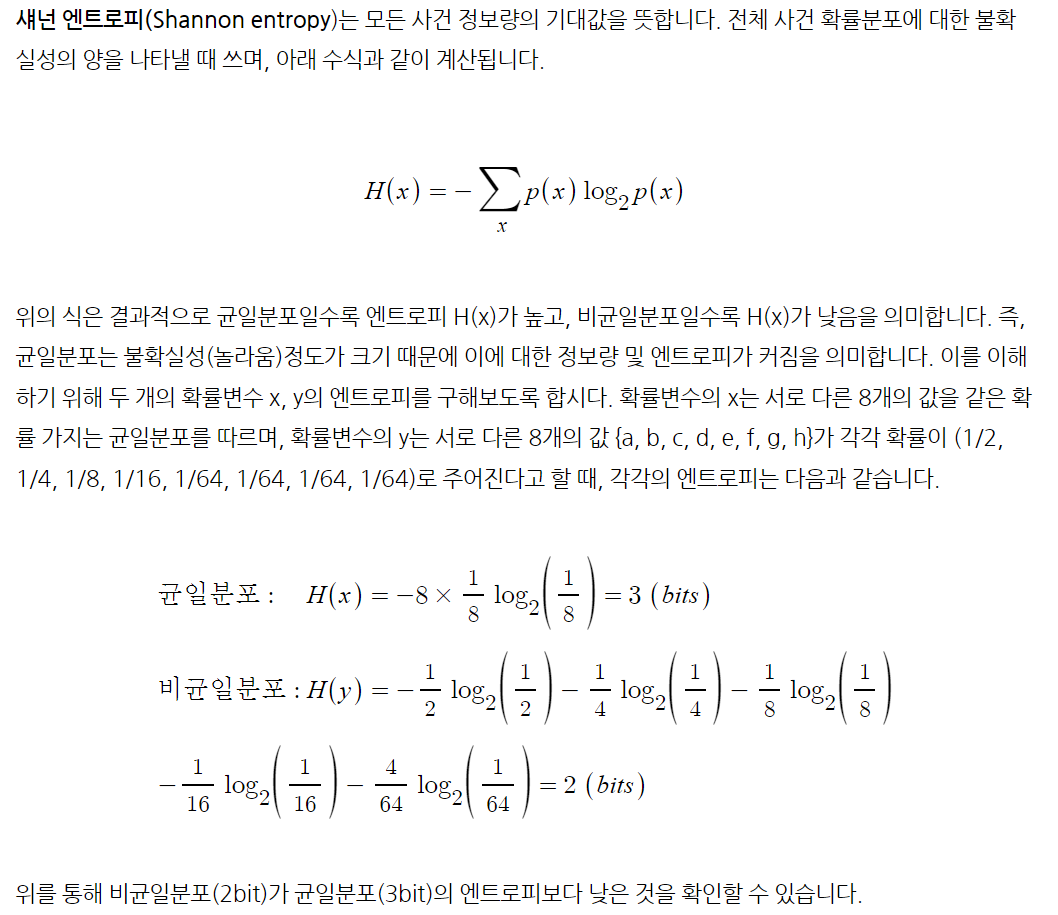

In [32]:
Image(filename="image/entropy.PNG")

Entropy (for data science) Clearly Explained!!!
StatQuest with Josh Starmer 

- Entropy = Low -> Random 균질
- Entropy = High -> Random 완전혼합

https://www.youtube.com/watch?v=YtebGVx-Fxw&ab_channel=StatQuestwithJoshStarmer

In [33]:
# 2019년 데이터만 추출
industry_19 = industry.loc[industry['year']==2019, ['sido','code','sector','employee']]
industry_19 = industry_19.sort_values(['sido', 'code'], ascending = True).rename(columns = {'employee':'employee_2019'})
industry_19

,sido,code,sector,employee_2019
807,강원,A,"농업, 임업 및 어업(01~03)",3165
811,강원,B,광업(05~08),4562
815,강원,C,제조업(10~34),61976
819,강원,D,"전기, 가스, 증기 및 공기조절 공급업(35)",3724
823,강원,E,"수도, 하수 및 폐기물 처리, 원료 재생업(36~39)",4928
827,강원,F,건설업(41~42),59981
831,강원,G,도매 및 소매업(45~47),88824
835,강원,H,운수 및 창고업(49~52),28574
839,강원,I,숙박 및 음식점업(55~56),108569
843,강원,J,정보통신업(58~63),8439


In [34]:
# 전국 i산업 종사자수 변수 생성
gb = industry_19.groupby(["sido"])["employee_2019"]

industry_19["sido_sum"] = gb.transform("sum")
industry_19

,sido,code,sector,employee_2019,sido_sum
807,강원,A,"농업, 임업 및 어업(01~03)",3165,670247
811,강원,B,광업(05~08),4562,670247
815,강원,C,제조업(10~34),61976,670247
819,강원,D,"전기, 가스, 증기 및 공기조절 공급업(35)",3724,670247
823,강원,E,"수도, 하수 및 폐기물 처리, 원료 재생업(36~39)",4928,670247
827,강원,F,건설업(41~42),59981,670247
831,강원,G,도매 및 소매업(45~47),88824,670247
835,강원,H,운수 및 창고업(49~52),28574,670247
839,강원,I,숙박 및 음식점업(55~56),108569,670247
843,강원,J,정보통신업(58~63),8439,670247


In [35]:
industry_19['p_x']= industry_19.employee_2019 / industry_19.sido_sum
industry_19

,sido,code,sector,employee_2019,sido_sum,p_x
807,강원,A,"농업, 임업 및 어업(01~03)",3165,670247,0.005
811,강원,B,광업(05~08),4562,670247,0.007
815,강원,C,제조업(10~34),61976,670247,0.092
819,강원,D,"전기, 가스, 증기 및 공기조절 공급업(35)",3724,670247,0.006
823,강원,E,"수도, 하수 및 폐기물 처리, 원료 재생업(36~39)",4928,670247,0.007
827,강원,F,건설업(41~42),59981,670247,0.089
831,강원,G,도매 및 소매업(45~47),88824,670247,0.133
835,강원,H,운수 및 창고업(49~52),28574,670247,0.043
839,강원,I,숙박 및 음식점업(55~56),108569,670247,0.162
843,강원,J,정보통신업(58~63),8439,670247,0.013


In [36]:
industry_19['ln_p_x']= np.log(industry_19.p_x)
industry_19

,sido,code,sector,employee_2019,sido_sum,p_x,ln_p_x
807,강원,A,"농업, 임업 및 어업(01~03)",3165,670247,0.005,-5.355
811,강원,B,광업(05~08),4562,670247,0.007,-4.990
815,강원,C,제조업(10~34),61976,670247,0.092,-2.381
819,강원,D,"전기, 가스, 증기 및 공기조절 공급업(35)",3724,670247,0.006,-5.193
823,강원,E,"수도, 하수 및 폐기물 처리, 원료 재생업(36~39)",4928,670247,0.007,-4.913
827,강원,F,건설업(41~42),59981,670247,0.089,-2.414
831,강원,G,도매 및 소매업(45~47),88824,670247,0.133,-2.021
835,강원,H,운수 및 창고업(49~52),28574,670247,0.043,-3.155
839,강원,I,숙박 및 음식점업(55~56),108569,670247,0.162,-1.820
843,강원,J,정보통신업(58~63),8439,670247,0.013,-4.375


In [37]:
industry_19['_px_ln_px']= -1 * industry_19.p_x * industry_19.ln_p_x
industry_19

,sido,code,sector,employee_2019,sido_sum,p_x,ln_p_x,_px_ln_px
807,강원,A,"농업, 임업 및 어업(01~03)",3165,670247,0.005,-5.355,0.025
811,강원,B,광업(05~08),4562,670247,0.007,-4.990,0.034
815,강원,C,제조업(10~34),61976,670247,0.092,-2.381,0.220
819,강원,D,"전기, 가스, 증기 및 공기조절 공급업(35)",3724,670247,0.006,-5.193,0.029
823,강원,E,"수도, 하수 및 폐기물 처리, 원료 재생업(36~39)",4928,670247,0.007,-4.913,0.036
827,강원,F,건설업(41~42),59981,670247,0.089,-2.414,0.216
831,강원,G,도매 및 소매업(45~47),88824,670247,0.133,-2.021,0.268
835,강원,H,운수 및 창고업(49~52),28574,670247,0.043,-3.155,0.135
839,강원,I,숙박 및 음식점업(55~56),108569,670247,0.162,-1.820,0.295
843,강원,J,정보통신업(58~63),8439,670247,0.013,-4.375,0.055


In [38]:
industry_19=industry_19.groupby(['sido'])[['_px_ln_px']].agg(['sum']).droplevel(axis=1,level=1).reset_index().rename(columns = {'_px_ln_px' : 'entropy'})
industry_19 = industry_19.sort_values('entropy', ascending = True)

industry_19

,sido,entropy
10,울산,2.298
15,충남,2.344
2,경남,2.361
16,충북,2.392
3,경북,2.393
1,경기,2.439
11,인천,2.456
9,세종,2.486
5,대구,2.489
14,제주,2.513


In [39]:
fig = px.bar(industry_19, 
             x="sido", 
             y="entropy", 
             template="simple_white"
            )
fig.show()

## 4. Gini Impurity Index (Gini-Simpson index)

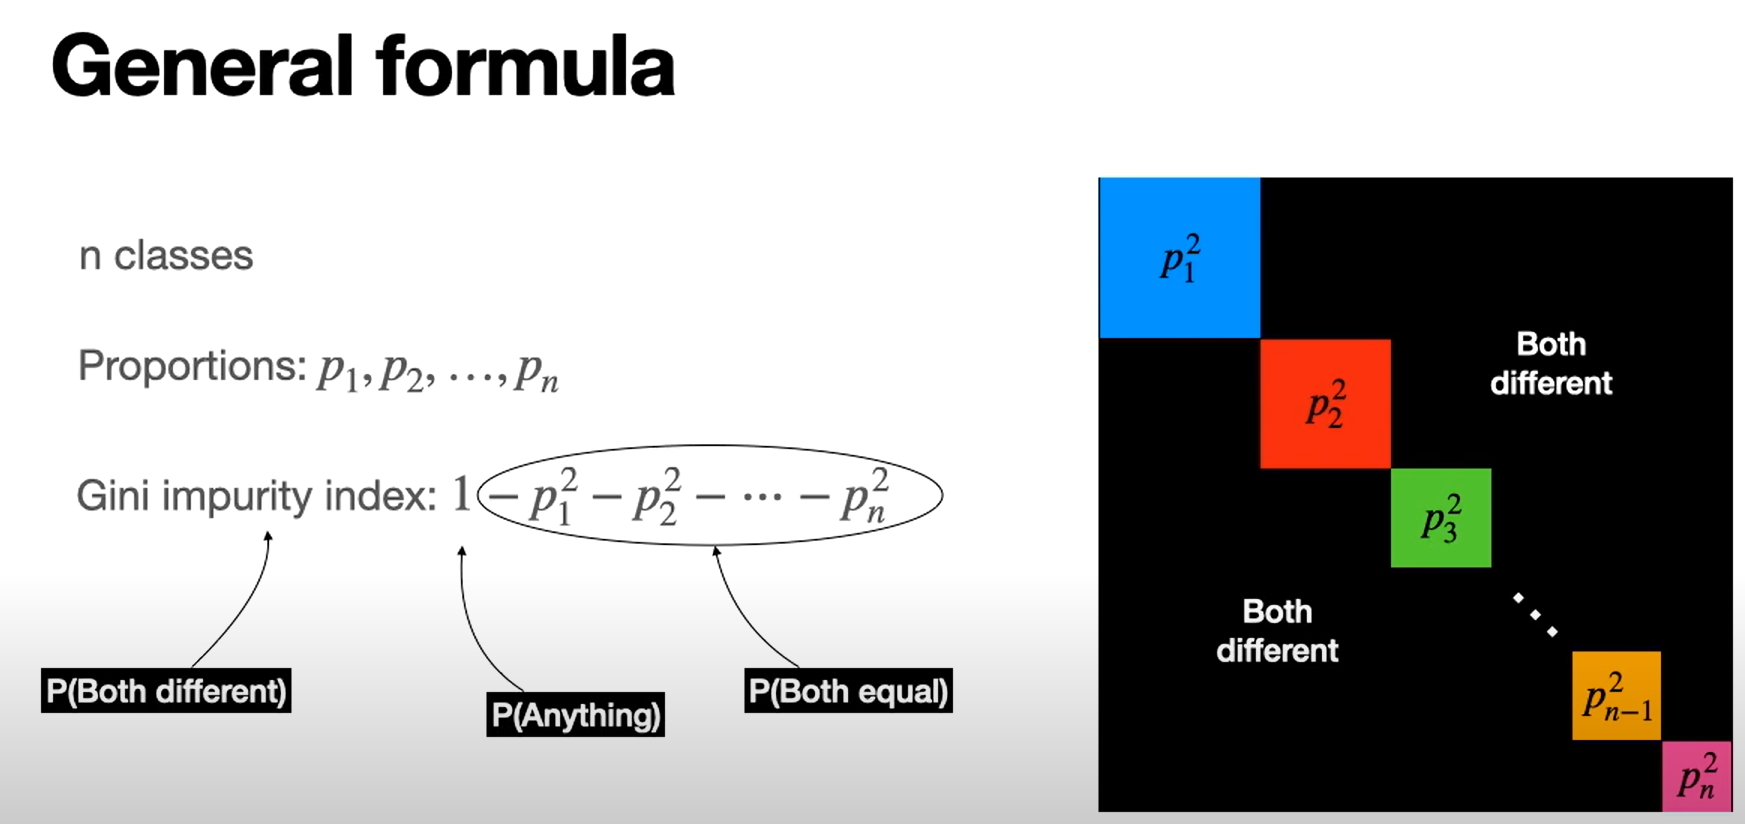

In [40]:
Image(filename="image/gini.PNG")

The Gini-Simpson index explained in 8 minutes!
Serrano.Academy

- The Gini-Simpson index = 0 -> Pure 균질
- The Gini-Simpson index = 1 -> Impure 완전혼합


https://www.youtube.com/watch?v=u4IxOk2ijSs&ab_channel=Serrano.Academy

In [41]:
# 2019년 데이터만 추출
industry_gini_19 = industry.loc[industry['year']==2019, ['sido','code','sector','employee']]
industry_gini_19 = industry_gini_19.sort_values(['sido', 'code'], ascending = True)
industry_gini_19

,sido,code,sector,employee
807,강원,A,"농업, 임업 및 어업(01~03)",3165
811,강원,B,광업(05~08),4562
815,강원,C,제조업(10~34),61976
819,강원,D,"전기, 가스, 증기 및 공기조절 공급업(35)",3724
823,강원,E,"수도, 하수 및 폐기물 처리, 원료 재생업(36~39)",4928
827,강원,F,건설업(41~42),59981
831,강원,G,도매 및 소매업(45~47),88824
835,강원,H,운수 및 창고업(49~52),28574
839,강원,I,숙박 및 음식점업(55~56),108569
843,강원,J,정보통신업(58~63),8439


In [42]:
pd.options.display.float_format = '{:20.6f}'.format


gb = industry_gini_19.groupby(["sido"])["employee"]
industry_gini_19["sido_sum"] = gb.transform("sum")


# 업종별 종사자수 Probability 제곱 변수 생성 
industry_gini_19["prob"] = industry_gini_19.employee / industry_gini_19.sido_sum
industry_gini_19["prob_sq"] = industry_gini_19["prob"] * industry_gini_19["prob"]

industry_gini_19

,sido,code,sector,employee,sido_sum,prob,prob_sq
807,강원,A,"농업, 임업 및 어업(01~03)",3165,670247,0.004722,0.000022
811,강원,B,광업(05~08),4562,670247,0.006806,0.000046
815,강원,C,제조업(10~34),61976,670247,0.092467,0.008550
819,강원,D,"전기, 가스, 증기 및 공기조절 공급업(35)",3724,670247,0.005556,0.000031
823,강원,E,"수도, 하수 및 폐기물 처리, 원료 재생업(36~39)",4928,670247,0.007353,0.000054
827,강원,F,건설업(41~42),59981,670247,0.089491,0.008009
831,강원,G,도매 및 소매업(45~47),88824,670247,0.132524,0.017563
835,강원,H,운수 및 창고업(49~52),28574,670247,0.042632,0.001817
839,강원,I,숙박 및 음식점업(55~56),108569,670247,0.161984,0.026239
843,강원,J,정보통신업(58~63),8439,670247,0.012591,0.000159


In [43]:
# gini_impurity 변수 생성

gini=industry_gini_19.groupby(['sido'])[['prob_sq']].agg(['sum']).droplevel(axis=1,level=1).reset_index().rename(columns = {'prob_sq' : 'p2_sum'})
gini['gini_impurity'] = 1-gini['p2_sum']
gini=gini.sort_values('gini_impurity', ascending = True)
gini

,sido,p2_sum,gini_impurity
10,울산,0.154241,0.845759
15,충남,0.142983,0.857017
2,경남,0.135432,0.864568
16,충북,0.131022,0.868978
3,경북,0.129443,0.870557
1,경기,0.117509,0.882491
11,인천,0.110342,0.889658
14,제주,0.106159,0.893841
9,세종,0.102722,0.897278
5,대구,0.102077,0.897923


In [44]:
fig = px.bar(gini, 
             x="sido", 
             y="gini_impurity", 
             template="simple_white"
            )
fig.show()

Understanding the Gini Coefficient
Singapore Department of Statistics (DOS) 

https://www.youtube.com/watch?v=BwSB__Ugo1s&ab_channel=SingaporeDepartmentofStatistics%28DOS%29